# Visual steering: raw image to live directions and generation

This notebook walks through input construction, two direction-building forwards, a three-strength live generation sweep, and built-in visualization. It reads no cached captions, tensors, or figures. The raw image is from COCO 2014 validation. This is an illustrative VSV run, not a dataset-level evaluation of VISTA.


## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

Optional environment settings: VLM_PROBING_REPOSITORY (default
ubc-tea/vlm-probe), VLM_PROBING_REF (default main), and
VLM_PROBING_COLAB_DIR (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [ ]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "ubc-tea/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get("VLM_PROBING_REF", "main")
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


## 1. Install and load the native VLM

Install `pip install "vlmprobe[transformers,visualization,notebooks]"`. This example loads a real 500M-parameter model; it is not a tiny mock model. No calibration or fitted weights are needed. GPU memory and time depend on image cropping and generation length. Generation deliberately replays the complete image/prefix without a KV cache.


In [1]:
import os
import hashlib
import urllib.request
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from vlmprobe import Prober, TokenMargin
from vlmprobe.visualization import plot_input, plot_intervention_curves

# This recipe targets the SmolVLM/Idefics3 image/chat contract.
# First run downloads the 500M model (~1 GB); CUDA is recommended.
model_id = os.environ.get("VLM_PROBING_MODEL", "HuggingFaceTB/SmolVLM-500M-Instruct")
device = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
dtype = torch.bfloat16 if device.startswith("cuda") else torch.float32
model = AutoModelForImageTextToText.from_pretrained(
    model_id, dtype=dtype, attn_implementation="eager",
).to(device).eval()
processor = AutoProcessor.from_pretrained(model_id)
probe = Prober(model, processor=processor)
assert model.config.model_type == "idefics3", "Use this recipe with SmolVLM; other models need their native input guide"
print({name: info for name, info in probe.describe()["methods"].items()
       if name.startswith("causal.")})
output_dir = Path(os.environ.get("VLM_PROBING_OUTPUT", "outputs/tutorials/causal"))
output_dir.mkdir(parents=True, exist_ok=True)


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

{'causal.patch': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'requires': 'residual sites', 'missing': None}, 'causal.path': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'requires': 'editable outputs at every decoder layer and receiver Q/K/V or final residual', 'missing': None}, 'causal.attribute': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'requires': 'differentiable residual sites', 'missing': None}, 'causal.steer': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'requires': 'residual sites', 'missing': None}, 'causal.knockout': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 

## 2. Read the original image and verify its source identity

The raw COCO validation image may be read from the repository’s bundled input images. Outside the repository this cell downloads the same file from COCO and checks its hash. No model results are loaded.


In [2]:
# A raw COCO image, not an attribution asset or cached model output.
filename = "COCO_val2014_000000310196.jpg"
expected_sha256 = "0dcc39d91764e59e0e01c11b92ec31320f094a87ca2dce5e0c56c4f1a361daf4"
custom_image = os.environ.get("VLM_PROBING_IMAGE")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "demos/assets/images" / filename).is_file()), None)
image_path = Path(custom_image) if custom_image else (root / "demos/assets/images" / filename if root else output_dir / filename)
if custom_image and not image_path.is_file():
    raise FileNotFoundError(image_path)
if not image_path.is_file():
    url = "https://s3.amazonaws.com/images.cocodataset.org/val2014/" + filename
    with urllib.request.urlopen(url, timeout=60) as response:
        image_path.write_bytes(response.read())
if not custom_image:
    assert hashlib.sha256(image_path.read_bytes()).hexdigest() == expected_sha256
image = Image.open(image_path).convert("RGB")


## 3. Prepare a native image prompt and an exact text-only reference

Positive input: image plus question. Negative input: the same tokenized question/chat context with the full image wrapper span removed. A gray image is a different contrast and is not VSV’s no-image reference. We show the preprocessing rather than importing it from a demo helper.


Positive prompt: <|im_start|>User:<image>Please help me describe the image in detail.<end_of_utterance>
Assistant:
Text-only reference: <|im_start|>User:Please help me describe the image in detail.<end_of_utterance>
Assistant:
Positive/reference token counts: 879 17


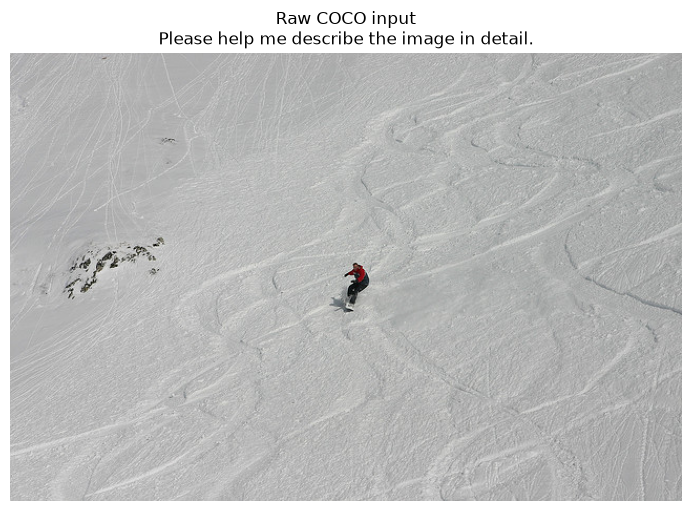

In [3]:
question = "Please help me describe the image in detail."
messages = [{"role": "user", "content": [
    {"type": "image"}, {"type": "text", "text": question},
]}]
prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
values = dict(processor(text=prompt, images=image, return_tensors="pt"))
positive = {key: value.to(device=device, dtype=dtype if value.is_floating_point() else value.dtype)
            if isinstance(value, torch.Tensor) else value for key, value in values.items()}
# SmolVLM surrounds all image crops/global image tokens with a contiguous wrapper span.
# Remove that entire span; preserve the exact tokenized text on either side.
wrapper_id = processor.fake_image_token_id
wrappers = (positive["input_ids"][0] == wrapper_id).nonzero().flatten()
assert wrappers.numel() >= 2, "Expected SmolVLM image wrapper tokens"
keep = torch.ones(positive["input_ids"].shape[1], dtype=torch.bool, device=device)
keep[int(wrappers[0]):int(wrappers[-1]) + 1] = False
negative = {"input_ids": positive["input_ids"][:, keep].clone(),
            "attention_mask": positive["attention_mask"][:, keep].clone()}
assert torch.equal(negative["input_ids"], positive["input_ids"][:, keep])
print("Positive prompt:", prompt)
print("Text-only reference:", processor.tokenizer.decode(negative["input_ids"][0]))
print("Positive/reference token counts:", positive["input_ids"].shape[1], negative["input_ids"].shape[1])
ax = plot_input(image, prompt=question, title="Raw COCO input")
ax.figure.savefig(output_dir / "causal-vsv-input.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Construct directions, intervene, and generate fresh continuations

At each layer, VSV subtracts the text-only last-context residual from the image-conditioned one. The intervention changes the original context-end prediction token and generated tokens, adds a fixed direction, and restores vector norms. Strengths are illustrative raw-residual values, not calibrated optima; stronger is not necessarily better. This is VSV only, without VISTA’s separate SLA decoding component.


In [4]:
# No training: directions are positive-minus-negative last-context residuals.
vectors = probe.causal.vsv(positive, negative, layers=None)
print("Direction construction:", vectors.metadata)
strengths = [0.0, 0.02, 0.05]
max_new_tokens = int(os.environ.get("VLM_PROBING_MAX_NEW_TOKENS", "32"))
# These are exact vocabulary-token logits, not complete word probabilities.
candidates = {word: processor.tokenizer.encode(word, add_special_tokens=False)[0]
              for word in ("person", "car")}
print("Fixed-prefix subwords:", {word: processor.tokenizer.decode([token])
                                  for word, token in candidates.items()})
responses = {word: [] for word in candidates}
captions = {}
for strength in strengths:
    method = vectors.configure(strength=strength, tokens="prediction")
    # All strengths see this same original prompt in this diagnostic.
    trace = method.forward(positive, direction=vectors.directions)
    for word, token in candidates.items():
        responses[word].append(float(trace.logits[0, -1, token]))
    del trace
    output = method.generate(positive, direction=vectors.directions,
                             max_new_tokens=max_new_tokens, do_sample=False)
    captions[strength] = output.metadata["decoded_text"][0]
    print(f"Strength {strength}: {captions[strength]}")
    output.save(output_dir / f"vsv_strength_{strength:g}")


Direction construction: {'construction': 'positive minus negative last-context residual', 'trained': False, 'paper_equation': 4, 'layers': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'actual_forward_passes': 2, 'tokens': 'last_prompt', 'positive_positions': [[0, 878]], 'negative_positions': [[0, 16]], 'model_id': 'HuggingFaceTB/SmolVLM-500M-Instruct (local cached copy)'}
Fixed-prefix subwords: {'person': 'person', 'car': 'car'}


Strength 0.0:  The image depicts a person engaged in an outdoor activity, specifically snowboarding. The individual is positioned in a dynamic and dynamic pose, with their body leaning forward and


Strength 0.02:  The image depicts a person engaged in a snowboarding activity. The individual is positioned in a dynamic pose, with their body leaning forward and their arms extended outwards,


Strength 0.05:  The image depicts a person snowboarding down a snow-covered slope. The snowboarder is in the center of the image, and the background features a snow


## 5. Visualize the fixed-prefix response and retain full generated text

Compare the generated captions for grounded detail, unsupported additions, and repetition. The curve uses the same original prompt for every strength, so generation divergence cannot explain its differences. It reports the first vocabulary subword only, not whole-word probability or a hallucination metric.


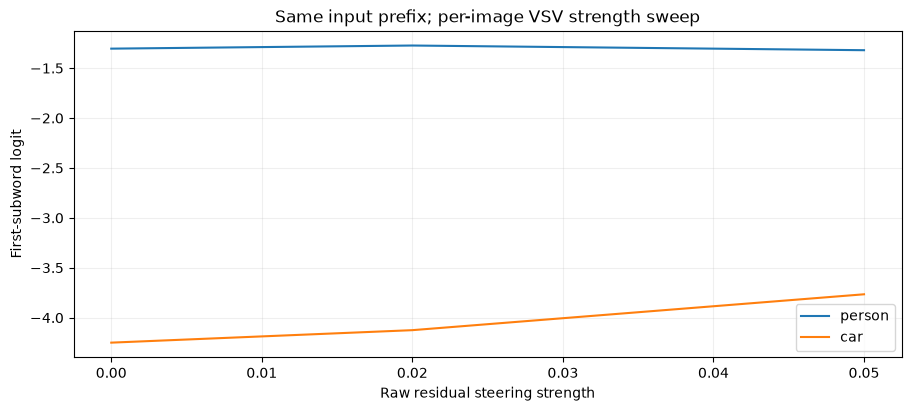

1774

In [5]:
ax = plot_intervention_curves(
    {word: {"x": strengths, "y": values} for word, values in responses.items()},
    xlabel="Raw residual steering strength", ylabel="First-subword logit",
    title="Same input prefix; per-image VSV strength sweep",
)
ax.figure.savefig(output_dir / "causal-vsv.png", dpi=150, bbox_inches="tight")
plt.show()
# Persist the complete generated continuations, not selected favorable excerpts.
import json
(output_dir / "vsv_captions.json").write_text(json.dumps({
    "model": model_id, "prompt": prompt, "construction": vectors.metadata,
    "max_new_tokens": max_new_tokens, "captions": captions,
    "candidate_ids": candidates, "fixed_prefix_logits": responses,
}, indent=2) + "\n")
